In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) -- 
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
# 1. Silence C++ backend warnings (Must be before importing/using TF operations)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

try:
    import tensorflow as tf
except:
    !uv pip install tensorflow
    import tensorflow as tf

import logging

# 2. Silence Python level TensorFlow/ABSL warnings
tf.get_logger().setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)

In [3]:
## -- keras library --
try:
    from scikeras.wrappers import KerasClassifier
except:
    !uv pip install -q scikeras
    from scikeras.wrappers import KerasClassifier

print()
# !pip show scikeras

In [4]:
!uv pip install -q ipywidgets
!uv pip install -q pygraphviz

!apt-get install -qq -y graphviz graphviz-dev && pip install -q pydot

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [6]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [7]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm import tqdm
from time import time, sleep

from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
# tf.get_logger().setLevel('ERROR')
warnings.simplefilter('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 1000)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [8]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [9]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## =================================================================================

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

Train shape: (699635, 23)
Test shape: (299844, 22)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>


In [10]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [12]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [13]:
ID = 'id'
TARGET = 'satisfaction'
train[TARGET] = train[TARGET].map({False: 0, True: 1})

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('Class', 'Type of Travel', 'Gender'),
    ('Class', 'Type of Travel', 'Age'),
    ('Flight Distance', 'Departure/Arrival time convenient'),
]
def feature_engineering(df, fit=False):
    # Fill NaNs
    for col in cat_cols:
        df[col] = df[col].fillna("missing")
    for col in num_cols:
        df[col] = df[col].fillna(0.0)

    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Count encoding
    for col in cat_cols + ['Leg room service']:
        count_name = f"_{col}_count"
        if fit:
            count_map = df[col].value_counts()
            category_map[count_name] = count_map
        else:
            count_map = category_map[count_name]
        df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_tst, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699635, 21)
X_test init shape: (299844, 21) 

init len(cat_cols): 4
init len(num_cols): 17 

len(new_cat_cols): 20
len(new_num_cols): 5 

prep len(cat_cols): 24
prep len(num_cols): 22 

X      prep shape: (699635, 46)
X_test prep shape: (299844, 46) 



In [14]:
X.nunique()

Age                                                      75
Flight Distance                                        3474
Inflight wifi service                                     6
Departure/Arrival time convenient                         6
Ease of Online booking                                    6
Gate location                                             6
Food and drink                                            6
Online boarding                                           6
Seat comfort                                              6
Inflight entertainment                                    6
On-board service                                          6
Leg room service                                          6
Baggage handling                                          5
Checkin service                                           6
Cleanliness                                               6
Departure Delay in Minutes                              167
Arrival Delay in Minutes                

In [15]:
_ = [c for c in X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {X.shape}")
X.head()

Train shape (699635, 46)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,Class_Type of Travel_Age_,Flight Distance_Departure/Arrival time convenient_
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,347952,576990,202194,327404,204124,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,351683,576990,497441,342212,182369,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,347952,576990,202194,327404,131580,0,2,2
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,351683,576990,202194,327404,182369,2,3,3
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,347952,122645,497441,327404,204124,3,4,4


# ML TRAINING

In [16]:
## -- SAMPLE MLP VIEWER --
n_features = len(FEATURES)
units = [256, 128, 64]

seq_layers = []
seq_layers.append(tf.keras.Input(shape=(n_features,)))
seq_layers.append(tf.keras.layers.BatchNormalization())

for i in range(len(units)):
    if i < (len(units) - 1):
        d = max(64, units[0] // (2**i))
    else:
        d = 64

    seq_layers.append(tf.keras.layers.Dense(units=d, activation='relu'))
    seq_layers.append(tf.keras.layers.BatchNormalization())
    seq_layers.append(tf.keras.layers.Dropout(0.1))

# Final output layer
seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

# 3. Create the Sequential model for the "head"
model = tf.keras.Sequential(seq_layers)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name='auc')]
)

model.summary()

I0000 00:00:1793136056.826573    8168 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793136056.828888    8168 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 46)             │           184 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,225 (215.72 KB)

 Trainable params: 54,237 (211.86 KB)

 Non-trainable params: 988 (3.86 KB)

In [17]:
def keras_mlp(meta, lr, units, act, drop):
    print(f"⚡️ Keras MLP Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]
    seq_layers = []

    # 1. Add Input and the critical initial BatchNormalization layer
    seq_layers.append(tf.keras.Input(shape=(n_features,)))
    seq_layers.append(tf.keras.layers.BatchNormalization())

    # 2. Loop explicitly over your units list to match the architecture
    for u in units:
        seq_layers.append(tf.keras.layers.Dense(units=u, activation=act))
        seq_layers.append(tf.keras.layers.BatchNormalization())
        seq_layers.append(tf.keras.layers.Dropout(drop))

    # 3. Final output layer
    seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

    # Compile model
    model = tf.keras.Sequential(seq_layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras MLP model ⚙️")


⚙️ Keras MLP model ⚙️


In [18]:
def keras_seq(meta, lr, units, act, drop):
    print(f"⚡️ Keras SEQUENTIAL Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dense(units[0], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[1], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[2], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras SEQUENTIAL model ⚙️")

⚙️ Keras SEQUENTIAL model ⚙️


In [19]:
if "digit_cols" in globals():
    print("✓ digit_cols available!")
else:
    print("𝗫 digit_cols unavailable!")

𝗫 digit_cols unavailable!


In [27]:
CHECKPOINT = "checkpoints/"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
os.makedirs(CHECKPOINT, exist_ok=True)

# -- Callbacks --
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        patience=7,
        mode="max",
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint( # -> save model
        filepath=f"{CHECKPOINT}best_model.model.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        # verbose=1
    ),
    # tf.keras.callbacks.ModelCheckpoint( # -> save weights
    #     filepath=f"{CHECKPOINT}best_model.weights.h5",
    #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
    #     save_best_only=True,
    #     save_weights_only=True,
    # ),
    # tf.keras.callbacks.ReduceLROnPlateau(
    #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
    #     factor=0.5,
    #     patience=5,
    #     min_lr=1e-6,
    #     verbose=1
    # ),
]

ACT   = 'selu'
UNITS = [512, 256, 64]
BATCH = 512 if torch.cuda.is_available() else 128
DROP  = 0.1

keras_params = {
    'model': keras_mlp,
    # model__shape=X_train.shape[1:],
    'batch_size': BATCH,
    'units': UNITS,
    'act': ACT ,
    'drop': DROP,
    'epochs': 50,
    'lr': 0.001,
    # ---------------------------------------------------------
    # # optimizer=tf.keras.optimizers.RMSprop(self.learning_rate),
    # optimizer=tf.keras.optimizers.Adam(self.learning_rate), # , weight_decay=None
    # loss="binary_crossentropy",
    # metrics=[tf.keras.metrics.AUC(name=self.eval_metric)],
    # ---------------------------------------------------------
    # fit__batch_size=GLOBAL_BATCH_SIZE,
    # validation_batch_size=10000,
    # predict__batch_size=10000,
    'random_state': 42,
    'shuffle': True,
    'verbose': 1,
    'callbacks': callbacks,
    # class_weight=get_weights(y_train, y_train),
}

keras_params

{'model': <function __main__.keras_mlp(meta, lr, units, act, drop)>,
 'batch_size': 512,
 'units': [512, 256, 64],
 'act': 'selu',
 'drop': 0.1,
 'epochs': 50,
 'lr': 0.001,
 'random_state': 42,
 'shuffle': True,
 'verbose': 1,
 'callbacks': [<keras.src.callbacks.early_stopping.EarlyStopping at 0x7beed1e32ad0>,
  <keras.src.callbacks.model_checkpoint.ModelCheckpoint at 0x7beed1e32c10>]}

In [28]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = f"KERAS{ACT}_mlp({X.shape[1]}_{UNITS[0]}_{str(DROP).split('.')[1]})"
print(f"\n🚀 Training {model_name} with {FOLDS } Folds", end=" | ")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))
fold_scores = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]
    X_tst = X_test.copy()

    # Target encoding
    if CFG.TE:
        _cats_  = [c for c in cat_cols if c.endswith("_cat_")]
        te_cols = combo_names + _cats_
        TE = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = [
        'Class_Type of Travel_Age_',
        'Flight Distance_Departure/Arrival time convenient_',
        ] + _cats_
        
        X_tr  = X_tr.drop(columns=te_cols)
        X_val = X_val.drop(columns=te_cols)
        X_tst = X_tst.drop(columns=te_cols)

    ## -- Define encoders --
    scaler_enc  = StandardScaler()
    ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
    num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
    cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
    ## ------------------------------------------------------------------------
    all_cats = [c for c in cat_cols if c not in te_cols]
    all_nums = [c for c in X_tr.columns if c not in all_cats]

    num_proc = make_pipeline(scaler_enc)
    cat_proc = make_pipeline(ohe_enc)

    preprocessor = make_column_transformer(
        (num_proc, all_nums),
        (cat_proc, all_cats),
        remainder='passthrough', n_jobs=-1,
    )
    X_tr  = preprocessor.fit_transform(X_tr, y_tr)
    X_val = preprocessor.transform(X_val)
    X_tst = preprocessor.transform(X_tst)
    # ------------------------------------------------------------------------------

    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")
    print("#"*16)
    print(f"### Fold {fold}/{FOLDS} ...")
    print("#"*16)

    model = KerasClassifier(**keras_params)

    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_tr, y_tr, validation_data=(X_val, y_val))

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds
    
    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds / FOLDS

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)
    print(f"seed={seeder}", end=" | ")
    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}\n")
    torch.cuda.empty_cache()

## -- CV results --
fold_results = {}
# model_name = model_name + f"({X_val.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s:.6f}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")


🚀 Training KERASselu_mlp(46_512_1) with 5 Folds | train=(559708, 48), valid=(139927, 48)

################
### Fold 1/5 ...
################
⚡️ Keras MLP Build
Epoch 1/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - auc: 0.9520 - loss: 0.2547 - val_auc: 0.9555 - val_loss: 0.2415
Epoch 2/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9549 - loss: 0.2422 - val_auc: 0.9561 - val_loss: 0.2377
Epoch 3/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9558 - loss: 0.2384 - val_auc: 0.9567 - val_loss: 0.2352
Epoch 4/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9564 - loss: 0.2358 - val_auc: 0.9575 - val_loss: 0.2329
Epoch 5/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9569 - loss: 0.2340 - val_auc: 0.9582 - val_loss: 0.2307
Epoch 6/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9572 - loss: 0.2328 - val_auc: 0.9585 - val_loss: 0.2297
Epoch 7/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9575 - loss: 0.2317 - val_auc: 0.9587 - val_loss:

In [22]:
# ==================================================
# 5-FOLD CV: KERASrelu_mlp(46_512_1) | (559708, 48)
# ==================================================
#  • Fold 1 AUC: 0.959768
#  • Fold 2 AUC: 0.956298
#  • Fold 3 AUC: 0.958436
#  • Fold 4 AUC: 0.957590
#  • Fold 5 AUC: 0.957029
# --------------------------------------------------
# OOF score: 0.957351
# AVG score: 0.957824 ± 0.001198
# --------------------------------------------------
# 7.65 mins

In [29]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print("-"*35)
print(f"AUC: {Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*35)

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print(f"{tt:.2f} mins")

-----------------------------------
AUC: KERASselu_mlp(46_512_1)_956606
-----------------------------------
           score
fold_1  0.959536
fold_2  0.954618
fold_3  0.957089
fold_4  0.955832
fold_5  0.955955
9.92 mins


In [30]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.182985
1,699636,0.931282
2,699637,0.884299
3,699638,0.041958
4,699639,0.053639
...,...,...
299839,999474,0.057020
299840,999475,0.032474
299841,999476,0.246418
299842,999477,0.025585


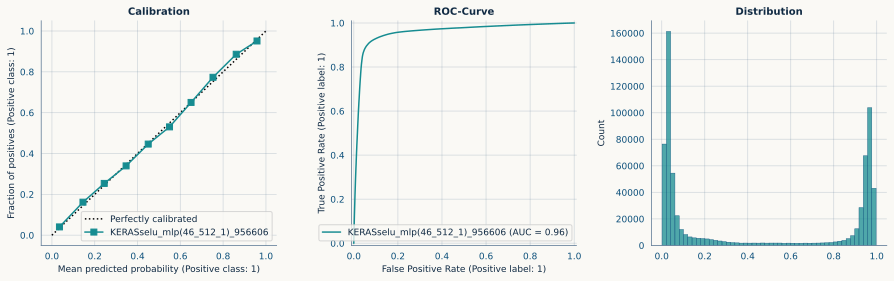

In [31]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [32]:
# !rm -r /kaggle/working

rm: cannot remove '/kaggle/working': Device or resource busy
